In [2]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt 


In [3]:
from sklearn.datasets import load_diabetes 
data = load_diabetes()

In [4]:
print(data.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [5]:
X = data.data 
y = data.target 

In [6]:
from sklearn.model_selection import train_test_split 
X_train , X_test , y_train , y_test = train_test_split(X , y , test_size = 0.2 , random_state = 45)

In [7]:
from sklearn.linear_model import LinearRegression
L = LinearRegression()


In [8]:
L.fit(X_train , y_train)

LinearRegression()

In [9]:
y_pred = L.predict(X_test)

In [10]:
from sklearn.metrics import r2_score , mean_squared_error 

print("r2_score", r2_score(y_test , y_pred))
print("MSE", mean_squared_error(y_test , y_pred))
print("RMSE", np.sqrt(mean_squared_error(y_test , y_pred)))

r2_score 0.5188113124539249
MSE 2374.3339396183187
RMSE 48.72713760953252


In [11]:
from sklearn.linear_model import Ridge 
R = Ridge(alpha = 0.0001)

In [12]:
R.fit(X_train , y_train)


Ridge(alpha=0.0001)

In [13]:
y_pred1 = R.predict(X_test)

In [14]:
from sklearn.metrics import r2_score , mean_squared_error 

print("r2_score", r2_score(y_test , y_pred1))
print("MSE", mean_squared_error(y_test , y_pred1))
print("RMSE", np.sqrt(mean_squared_error(y_test , y_pred1)))

r2_score 0.518973263588495
MSE 2373.5348225872626
RMSE 48.718937001819555


## overfitting & underfitting kaise hota h 


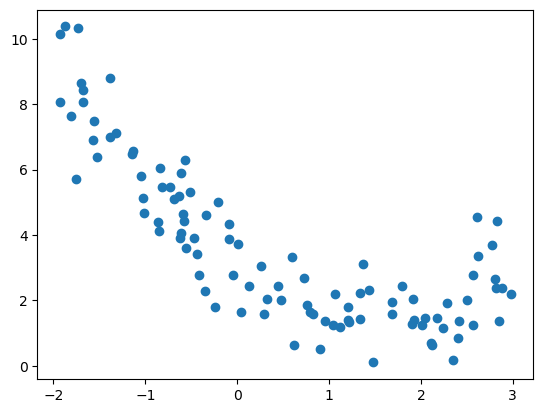

In [15]:

m = 100
x1 = 5 * np.random.rand(m , 1) - 2 
x2 = 0.7 * x1 ** 2 - 2 * x1 + 3 +  np.random.randn(m , 1)

plt.scatter(x1 , x2)
plt.show()

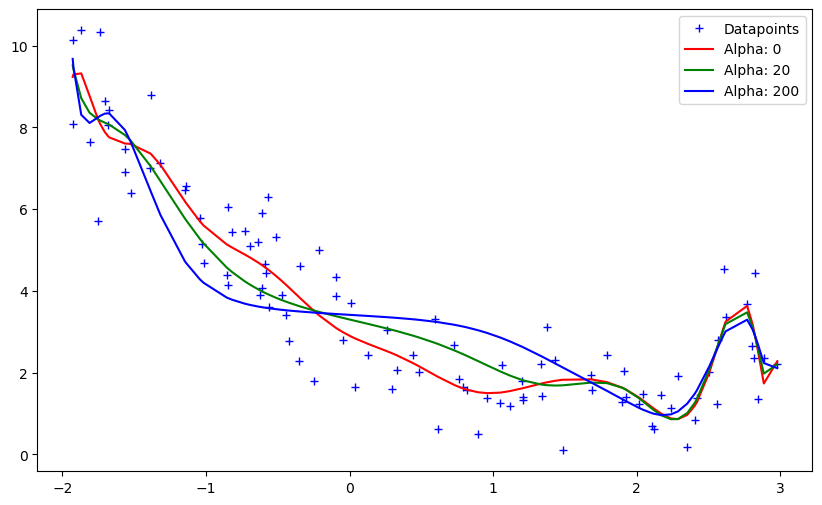

In [21]:
from sklearn.pipeline import Pipeline 
from sklearn.preprocessing import PolynomialFeatures

def get_pred_ridge(x1 , x2 , alpha):
    model = Pipeline([
        ('poly_feats' , PolynomialFeatures(degree = 16)),
        ('ridge' , Ridge(alpha=alpha))
        
    ])
    model.fit(x1 , x2)
    return model.predict(x1)

alpha = [0 , 20 , 200]

cs = ['r' , 'g' , 'b']

plt.figure(figsize = (10 , 6))
plt.plot(x1 , x2 , 'b+' , label = 'Datapoints')

for alpha , c in zip(alpha , cs):
    preds = get_pred_ridge(x1 , x2 , alpha)
    # plot 
    plt.plot(sorted(x1[:,0]) , preds[np.argsort(x1[:,0])] , c , label = 'Alpha: {}'.format(alpha))

plt.legend()
plt.show()